Este notebook tem como objetivo explorar os datasets sobre a temperatura global anual, o forçante radiativo efetivo global e o indice oceanico relativo do El Niño, a fim de descobrir possíveis correlações entre os dados coletados. 

O forçante radiativo é a mudança no balanço de energia da Terra causada por algum fator externo, medida em watts por metro quadrado (W/m²). Um forçante de +1 W/m² significa que, em média, cada metro quadrado do topo da atmosfera passa a receber 1 watt a mais do que emite.

Referências dos datasets:

Global Temperature - Earth Indicator: https://science.nasa.gov/earth/explore/earth-indicators/global-temperature/

forcing-timeseries: https://github.com/ClimateIndicator/forcing-timeseries



### Leitura dos dados

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ERF_PATH = '../tratamento/dados_tratados/dados_analise_climatica/ERF_best_aggregates.csv'
TEMP_PATH = '../tratamento/dados_tratados/dados_analise_climatica/temperatura_global.csv'
RONI_PATH = '../tratamento/dados_tratados/dados_el_nino/dados_El_nino_RONI.csv'
ONI_PATH = '../tratamento/dados_tratados/dados_el_nino/dados_El_nino_ONI.csv'

erf_df = pd.read_csv(ERF_PATH, index_col=[0])
temp_df = pd.read_csv(TEMP_PATH)
roni_df = pd.read_csv(RONI_PATH)
oni_df = pd.read_csv(ONI_PATH)

### Análise de Distribuição 

#### dados de anomalia da temperatura no pacífico equatorial central-leste.

agrupamos os datasets ONI e RONI em eventos únicos de ocorrência do el nino, onde cada evento representa uma seqência de semestres na fase de El-Niño, aplicamos uma função max para exibir o pico do valor da anomalia de temperatura de cada evento.

In [58]:
df = oni_df.copy()
is_el = df['FASE'] == 'El Niño'
df['evento'] = (is_el != is_el.shift()).cumsum()

df = df[df['FASE'] == 'El Niño']
df['evento'] = df['evento']/2
df['evento'] = df['evento'].astype('int')

oni_anom_evento = df

df = roni_df.copy()
is_el = df['FASE'] == 'El Niño'
df['evento'] = (is_el != is_el.shift()).cumsum()

df = df[df['FASE'] == 'El Niño']
df['evento'] = df['evento']/2
df['evento'] = df['evento'].astype('int')

roni_anom_evento = df

df.head(100)



,SEAS,YR,ANOM,FASE,evento
15,MAM,1951,0.63,El Niño,1
16,AMJ,1951,0.59,El Niño,1
17,MJJ,1951,0.69,El Niño,1
18,JJA,1951,0.79,El Niño,1
19,JAS,1951,0.97,El Niño,1
...,...,...,...,...,...
392,ASO,1982,1.64,El Niño,10
393,SON,1982,2.03,El Niño,10
394,OND,1982,2.24,El Niño,10
395,NDJ,1982,2.36,El Niño,10


In [59]:
df = oni_anom_evento.copy()
df = (
    df.groupby('evento')
    .agg(anom_max_evento=('ANOM', 'max'),
         YR=('YR', 'max'),
         n_trimestres=('ANOM', 'size'))
)
oni_anom_max_evento = df
df.head(100)

df = roni_anom_evento.copy()
df = (
    df.groupby('evento')
    .agg(anom_max_evento=('ANOM', 'max'),
         YR=('YR', 'max'),
         n_trimestres=('ANOM', 'size'))
)
roni_anom_max_evento = df


### plotamos os dados ONI e RONI

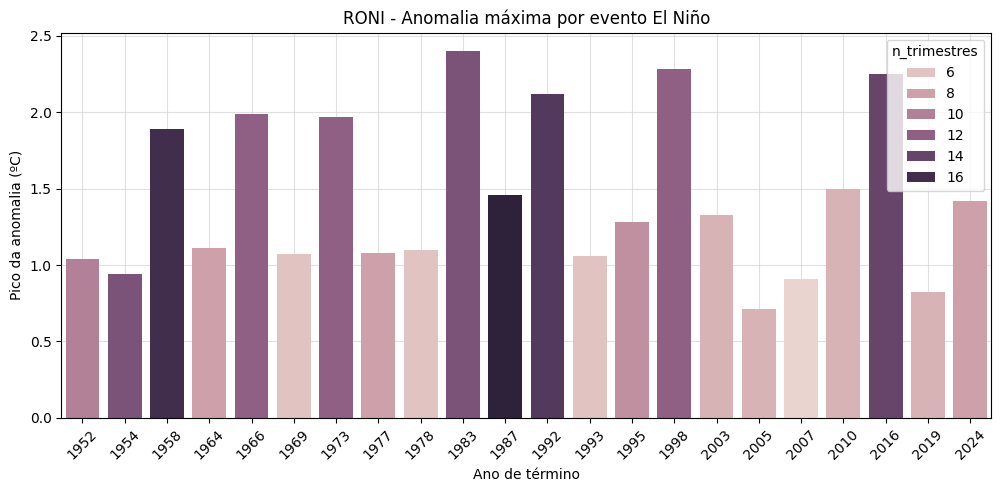

In [60]:

fig, ax = plt.subplots(figsize= [12,5])

ax = sns.barplot(data=roni_anom_max_evento, x= 'YR', y='anom_max_evento', hue='n_trimestres' )
ax.set_ylim(bottom=0)
ax.set_title('RONI - Anomalia máxima por evento El Niño')
ax.tick_params(axis= 'x',rotation=45)
ax.set_xlabel('Ano de término')
ax.set_ylabel('Pico da anomalia (ºC)')

ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)  # deixa a grade atrás da linha
plt.show()

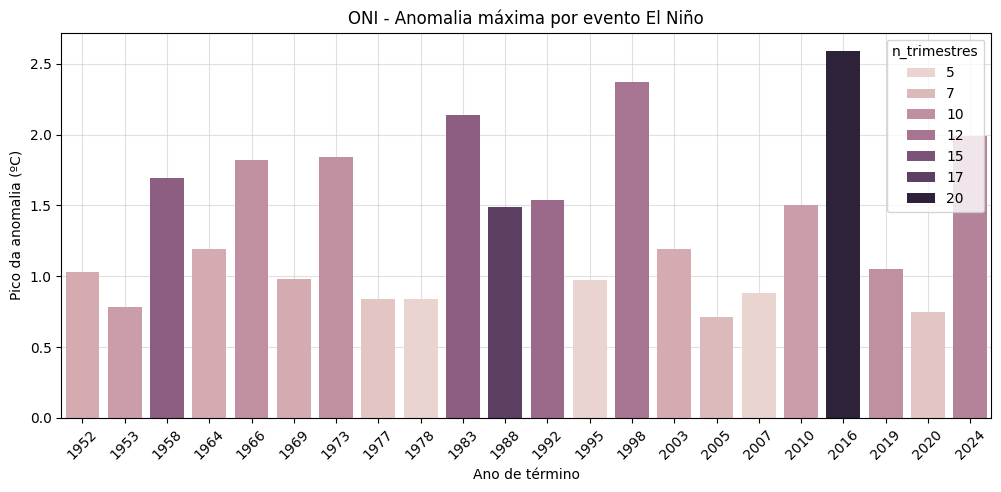

In [61]:
import seaborn as sns
fig, ax = plt.subplots(figsize= [12,5])

ax = sns.barplot(data=oni_anom_max_evento, x= 'YR', y='anom_max_evento', hue='n_trimestres' )
ax.set_ylim(bottom=0)
ax.set_title('ONI - Anomalia máxima por evento El Niño')
ax.tick_params(axis= 'x',rotation=45)
ax.set_xlabel('Ano de término')
ax.set_ylabel('Pico da anomalia (ºC)')

ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)  # deixa a grade atrás da linha
plt.show()

### análise sobre a sequência de trimestres seguidos em cada evento

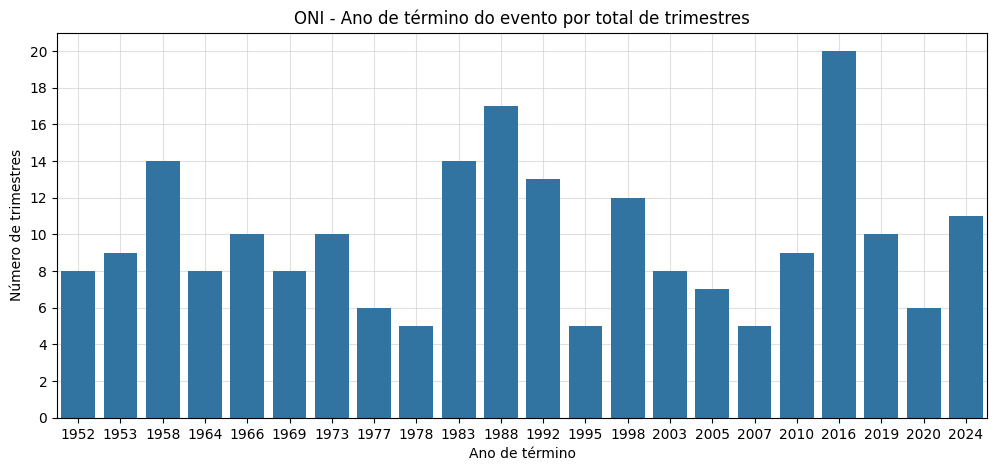

In [62]:
fig, ax = plt.subplots(figsize=[12, 5])

ax = sns.barplot(data=oni_anom_max_evento, x= 'YR', y='n_trimestres' )
ax.set_yticks(range(0, 21, 2))

ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)  # deixa a grade atrás da linha
ax.set_title('ONI - Ano de término do evento por total de trimestres')
ax.set_xlabel('Ano de término')
ax.set_ylabel('Número de trimestres')
plt.show()

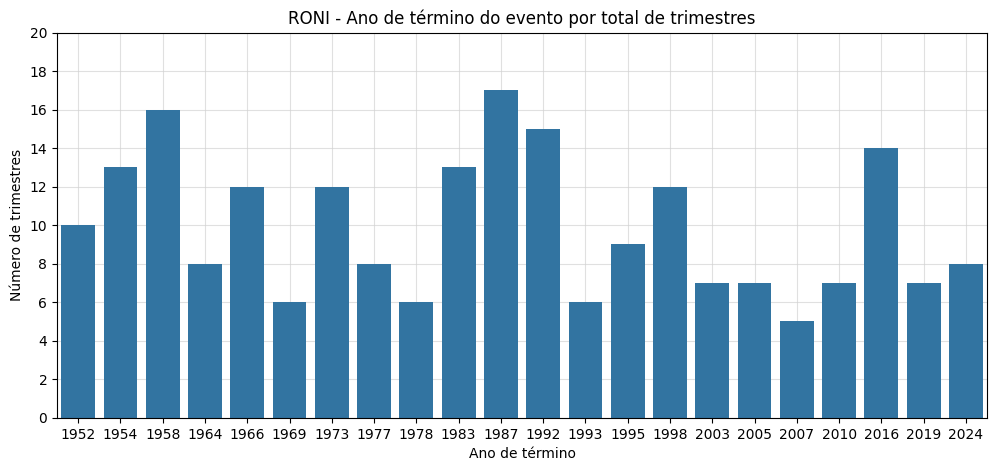

In [63]:
fig, ax = plt.subplots(figsize=[12, 5])

ax = sns.barplot(data=roni_anom_max_evento, x= 'YR', y='n_trimestres' )
ax.set_yticks(range(0, 21, 2))

ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)  # deixa a grade atrás da linha
ax.set_title('RONI - Ano de término do evento por total de trimestres')
ax.set_xlabel('Ano de término')
ax.set_ylabel('Número de trimestres')
plt.show()

### Distribuição da anomalia de temperatura por evento

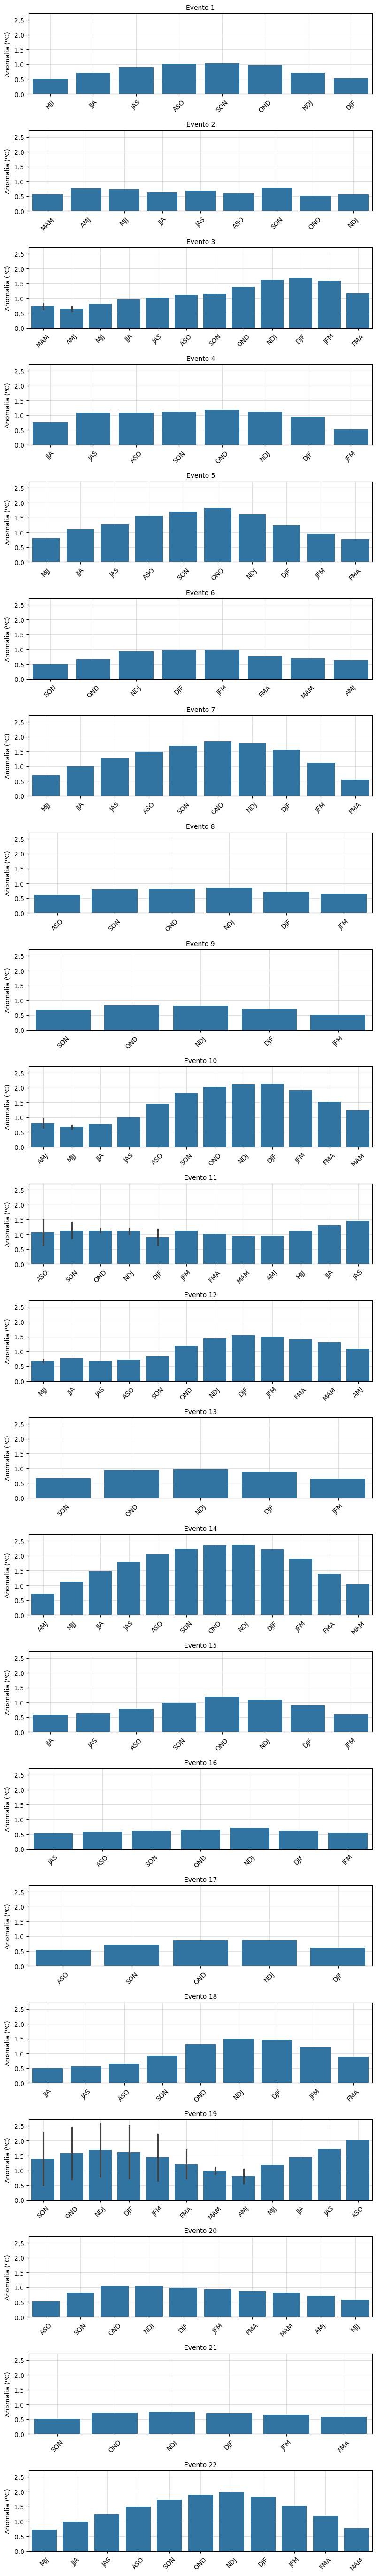

In [64]:

eventos = sorted(oni_anom_evento['evento'].unique())
fig, axes = plt.subplots(oni_anom_max_evento.index.size, 1, sharey=True, squeeze=False, figsize=(8, 2.5 * len(eventos)))
cnt = 1

axes = axes.ravel()
for ax in axes:
    df = oni_anom_evento[oni_anom_evento['evento'] == cnt].copy()
    ax = sns.barplot(data= df, x='SEAS', y='ANOM', ax=ax)
    ax.set_title(f'Evento {cnt}', fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Anomalia (ºC)')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
    ax.set_axisbelow(True)
    cnt += 1

plt.tight_layout()
plt.show()


### Linhas de regressão dos dados ONI e RONI

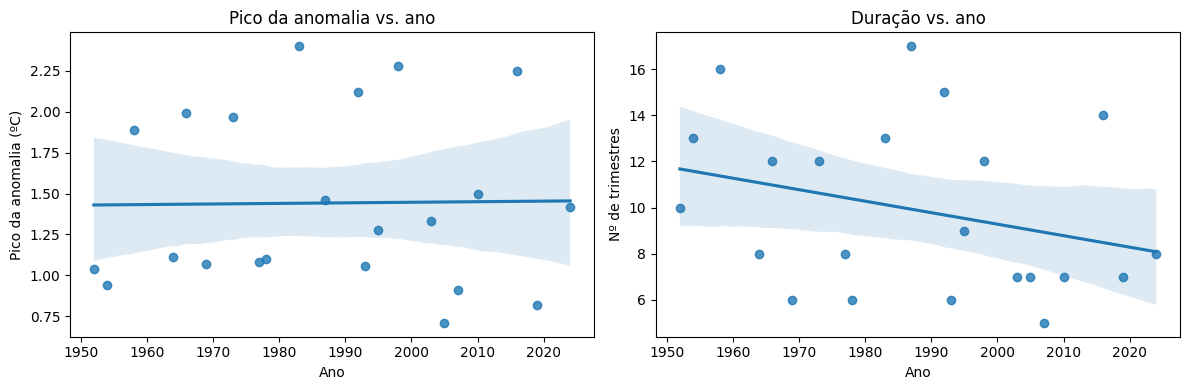

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.regplot(data=roni_anom_max_evento, x='YR', y='anom_max_evento', ax=axes[0])
axes[0].set_title('Pico da anomalia vs. ano')
axes[0].set_ylabel('Pico da anomalia (ºC)')
axes[0].set_xlabel('Ano')

sns.regplot(data=roni_anom_max_evento, x='YR', y='n_trimestres', ax=axes[1])
axes[1].set_title('Duração vs. ano')
axes[1].set_ylabel('Nº de trimestres')
axes[1].set_xlabel('Ano')

plt.tight_layout()
plt.show()

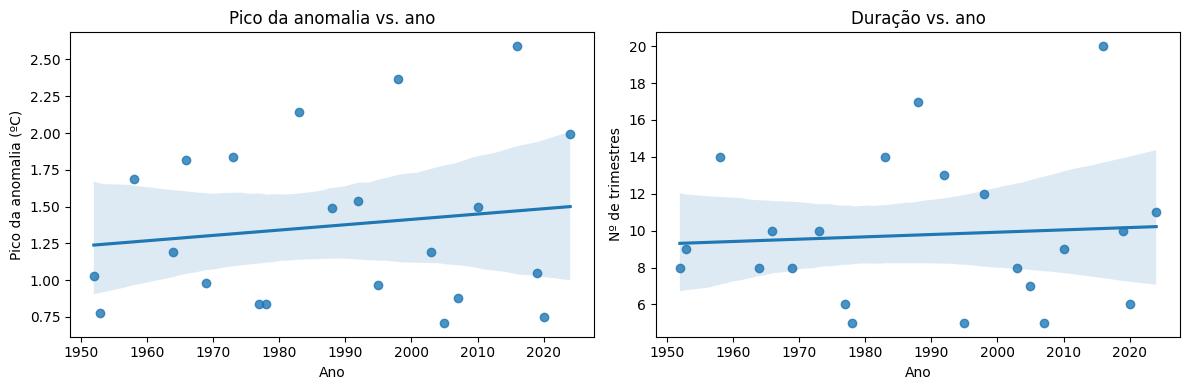

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.regplot(data=oni_anom_max_evento, x='YR', y='anom_max_evento', ax=axes[0])
axes[0].set_title('Pico da anomalia vs. ano')
axes[0].set_ylabel('Pico da anomalia (ºC)')
axes[0].set_xlabel('Ano')

sns.regplot(data=oni_anom_max_evento, x='YR', y='n_trimestres', ax=axes[1])
axes[1].set_title('Duração vs. ano')
axes[1].set_ylabel('Nº de trimestres')
axes[1].set_xlabel('Ano')

plt.tight_layout()
plt.show()

### Dados do forçante radiativo global

O forçamento radiativo efetivo (ERF, em W/m²) mede a variação no balanço de energia da Terra causada por um agente climático, já considerando os ajustes rápidos da atmosfera. Valores positivos indicam aquecimento e valores negativos indicam resfriamento. Os dados usados aqui correspondem à estimativa central, o percentil 5 e o percentil 95 da série de ERF, com valores anuais de 1750 a 2025 e uma coluna para cada agente.

O gráfico abaixo mostra, para o período de 1950 a 2025, as contribuições de dois grupos de agentes em áreas empilhadas:

- **Gases de efeito estufa de longa vida :** CO₂, CH₄, N₂O e gases halogenados. A altura total da pilha é o forçamento combinado desses gases.
- **Aerossóis :** interação com a radiação e interação com as nuvens. Eles refletem a luz solar e tornam as nuvens mais brilhantes, o que causa um efeito de resfriamento que compensa parte do aquecimento dos gases.

O gráfico mostra que o forçamento positivo cresce de forma contínua ao longo do período, com o CO₂ como o maior componente. O resfriamento dos aerossóis é menor em magnitude e tem menos incerteza associada ao seu padrão de crescimento, mas ainda é relevante. O forçamento total também inclui outros agentes (ozônio, uso do solo, solar, vulcânico etc.) que não aparecem nesta figura.

In [67]:
def plot_erf_stack(
    df,
    gases=('CO2', 'CH4', 'N2O', 'halogen'),
    aerossois=('aerosol-radiation_interactions', 'aerosol-cloud_interactions'),
    labels_gases=('CO₂', 'CH₄', 'N₂O', 'Halogenados'),
    labels_aerossois=('Aerossóis (interação com radiação)', 'Aerossóis (interação com nuvens)'),
    ano_inicio=1880,
    ano_fim=2026,
    passo_xticks=5,
    figsize=(10, 5),
    ax=None,
):

    fig, ax = plt.subplots(figsize=(10, 5))

    gases = ['CO2', 'CH4', 'N2O', 'halogen']
    aerossois = ['aerosol-radiation_interactions', 'aerosol-cloud_interactions']

    cores_gases = sns.color_palette('deep', n_colors=len(gases))
    cores_aer = sns.color_palette('pastel', n_colors=len(aerossois))

    ax.stackplot(
        df.index, [df[g] for g in gases], 
        labels=labels_gases,
        colors=cores_gases,
        alpha=0.85,
    )

    ax.stackplot(
        df.index,
        [df[a] for a in aerossois],
        labels=labels_aerossois,
        colors=cores_aer,
        alpha=0.85,
    )

    ax.set_xticks(range(ano_inicio,ano_fim, passo_xticks))
    ax.set_ylabel('ERF (W/m²)')
    ax.set_xlabel('Ano')
    ax.set_xlim(left=1950, right=2026)
    ax.tick_params(axis= 'x',rotation=45)
    ax.legend(loc='upper left', title='Gases de longa vida')

    ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
    ax.set_axisbelow(True) 

    return ax


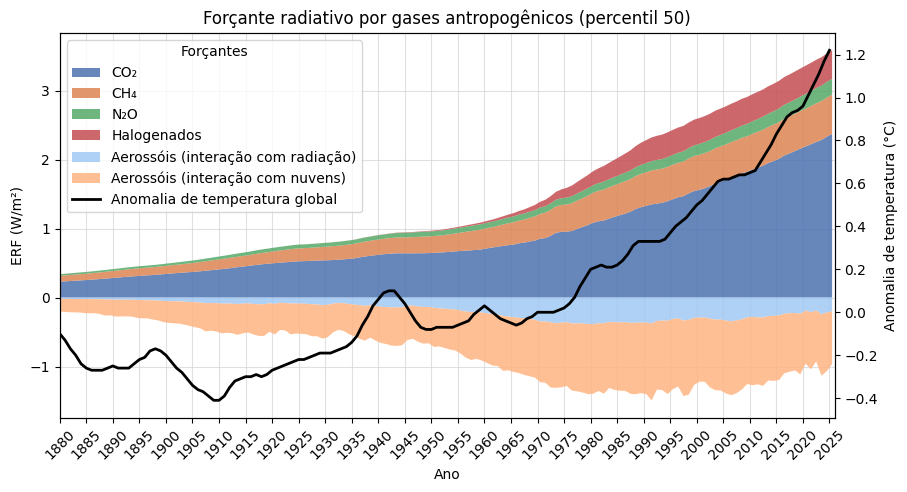

In [68]:
ax = plot_erf_stack(erf_df)
ax.set_title('Forçante radiativo por gases antropogênicos (percentil 50)')
ax2 = ax.twinx()

ax2.plot(temp_df['Year'], temp_df['Lowess(5)'],
         color='black', linewidth=2, label='Anomalia de temperatura global')
ax2.set_ylabel('Anomalia de temperatura (°C)')
ax2.set_xlim(1880, 2026)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', title='Forçantes')

plt.show()

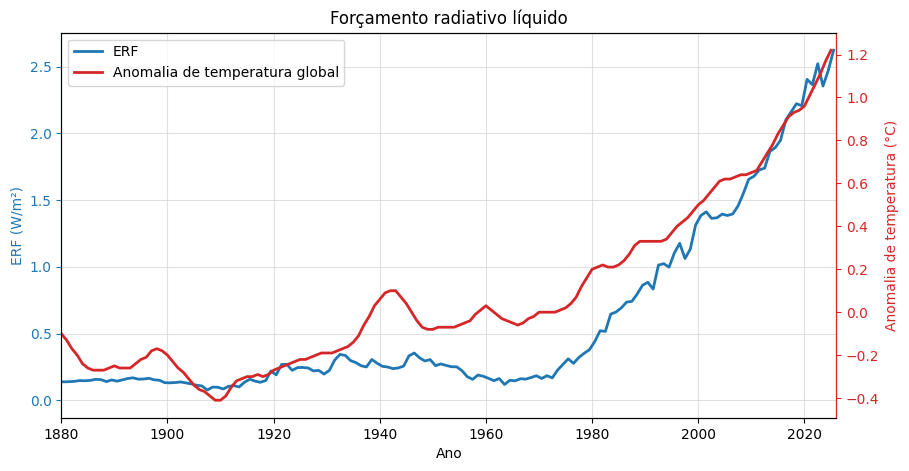

In [69]:
cor_erf = 'tab:blue'
cor_temp = 'tab:red'

erf_df['liquido'] = erf_df[['CO2','CH4','N2O','halogen',
                            'aerosol-radiation_interactions',
                            'aerosol-cloud_interactions']].sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(erf_df['liquido'], color=cor_erf, linewidth=2, label='ERF')
ax.grid(True, color='lightgray', linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)
ax.set_title('Forçamento radiativo líquido')
ax.set_xlabel('Ano')
ax.set_ylabel('ERF (W/m²)', color=cor_erf)
ax.tick_params(axis='y', colors=cor_erf)
ax.spines['left'].set_color(cor_erf)
ax.set_xlim(1880, 2026)

ax2 = ax.twinx()
ax2.plot(temp_df['Year'], temp_df['Lowess(5)'],
         color=cor_temp, linewidth=2, label='Anomalia de temperatura global')
ax2.set_ylabel('Anomalia de temperatura (°C)', color=cor_temp)
ax2.tick_params(axis='y', colors=cor_temp)
ax2.spines['right'].set_color(cor_temp)
ax2.set_xlim(1880, 2026)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')

plt.show()

In [70]:
import pandas as pd
import numpy as np
from scipy import stats

# Coloca o índice (ano .5) como coluna inteira
erf_aux = erf_df.copy()
erf_aux['Year'] = erf_aux.index.astype(int)
erf_aux = erf_aux[erf_aux['Year'] >= 1880]   # período moderno

temp_aux = temp_df[['Year', 'Lowess(5)']].copy()

merged = pd.merge(temp_aux, erf_aux, on='Year', how='inner')
print(f"N observações: {len(merged)}")

N observações: 146


In [71]:
x = merged['liquido'].to_numpy()      # ou 'total', 'liquido'
y = merged['Lowess(5)'].to_numpy()

# 1) Pearson bruto
r_pear, p_pear = stats.pearsonr(x, y)

# 2) Spearman (robusto a monotonicidade não-linear)
r_spear, p_spear = stats.spearmanr(x, y)

# 3) Pearson sobre primeiras diferenças (remove tendência)
#    Mede se variações ano-a-ano do ERF acompanham variações da temperatura
dx = np.diff(x)
dy = np.diff(y)
r_diff, p_diff = stats.pearsonr(dx, dy)

# 4) Pearson sobre resíduos de uma regressão linear (detrend)
from scipy.signal import detrend
r_det, p_det = stats.pearsonr(detrend(x), detrend(y))

print(f"Pearson bruto:      r = {r_pear:.3f}  (p = {p_pear:.1e})")
print(f"Spearman:           ρ = {r_spear:.3f}  (p = {p_spear:.1e})")
print(f"Pearson detrended:  r = {r_det:.3f}  (p = {p_det:.1e})")
print(f"Pearson Δ (1ª dif): r = {r_diff:.3f}  (p = {p_diff:.1e})")

Pearson bruto:      r = 0.960  (p = 1.3e-81)
Spearman:           ρ = 0.877  (p = 1.3e-47)
Pearson detrended:  r = 0.907  (p = 4.4e-56)
Pearson Δ (1ª dif): r = 0.211  (p = 1.1e-02)
